# 🧬 04 · The Word2Vec Model

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 4 of 9
> Course notes: page 10 (*"Word2Vec paper … pick up one word → want to predict next word"*, the $x\to V\to h\to U\to z\to$ softmax picture, *"No bias, no act. func except softmax. No. of parameters = 2×d×n"*), page 11 (*"Where are my vectors? Each column of V"*), page 13 (*"influenced just by I? No … we need other words' influence as well"*) · Xin Rong, *word2vec Parameter Learning Explained*

Notebook 02 **counted** neighbours and then compressed the counts. Word2vec (Mikolov et al., 2013) skips the counting: it sets up a tiny neural network whose only job is to **predict a neighbouring word**, and trains it on billions of (word, neighbour) pairs. The network is useless as a predictor – what we keep is the weight matrix, whose columns turn out to be excellent word vectors.

This notebook builds the model and its training data. Training comes in notebooks 05–06.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | The two training tasks: **skip-gram** (word → neighbours) and **CBOW** (neighbours → word) |
| 2 | The architecture $x\xrightarrow{V}h\xrightarrow{U}z\xrightarrow{\text{softmax}}y$, with all shapes |
| 3 | Why $h=Vx$ is just a **column lookup** |
| 4 | Counting the $2dn$ parameters |
| 5 | What an *untrained* model predicts, and what $E=-\log y_o$ is at the start |
| 6 | *"Where are my vectors?"* – the columns of $V$ |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)

---
## 1 · The variables

### 📖 Notation for the word2vec notebooks (same as the course notes, pages 10–14)

| Symbol | Shape | Meaning |
|---|---|---|
| $n$ | number | vocabulary size: how many different words we know |
| $d$ | number | embedding size: how many numbers describe one word (notes: typically 300) |
| $w_k$ | – | the $k$-th word of the vocabulary, $k=1..n$ |
| $x$ | $n\times1$ | one-hot vector of the **input** word: all zeros except a 1 at its index |
| $V$ | $d\times n$ | **input** matrix. Column $k$, written $v_k$, is the **word vector** of $w_k$ |
| $h=Vx$ | $d\times1$ | hidden vector. Because $x$ is one-hot, $h$ is simply the column $v_c$ of the input word $c$ |
| $U$ | $n\times d$ | **output** matrix. Row $k$, written $u_k$, is the "output vector" of $w_k$ |
| $z=Uh$ | $n\times1$ | one score per vocabulary word: $z_k=u_k\cdot h$ |
| $y=\text{softmax}(z)$ | $n\times1$ | probabilities: $y_k=e^{z_k}/\sum_{m}e^{z_m}$ = predicted chance that $w_k$ is the context word |
| $o$ | index | the **true** output (context) word of this training example |
| $E=-\log y_o$ | number | error: minus the log of the probability given to the right word |
| $\delta_{ok}$ | number | Kronecker delta: 1 if $o=k$, else 0 |
| $\eta$ | number | learning rate |

No biases and no activation function except the final softmax, so the model has exactly $2\ d\ n$ parameters (notes, page 10).
New in this notebook:

| Symbol | Meaning |
|---|---|
| $m$ | window size: neighbours up to $m$ positions left and right are "context" |
| $c$ | index of the **center** (input) word |
| pair $(c,o)$ | one skip-gram training example: input word $c$, word to predict $o$ |

---
## 2 · The training task: predict a neighbour 🎯

From the notes: *"I like going **to** my old house" – pick up one word, want to predict the words around it.* There are two mirror-image ways to turn a sentence into training examples:

| | input | output to predict | notes |
|---|---|---|---|
| **skip-gram** | the center word | **each** neighbour, one at a time | "pick up one word → predict" |
| **CBOW** (continuous bag of words) | **all** neighbours together | the center word | "influenced just by *I*? No – we need other words' influence as well" |

We start with the corpus from notebooks 02–03 (sentences with known hidden meanings).

In [2]:
PEOPLE = {   # word: (status, gender, age)
    "king": ("royal", "male", "adult"),     "queen": ("royal", "female", "adult"),
    "prince": ("royal", "male", "young"),   "princess": ("royal", "female", "young"),
    "man": ("common", "male", "adult"),     "woman": ("common", "female", "adult"),
    "boy": ("common", "male", "young"),     "girl": ("common", "female", "young"),
}
POOLS = {    # context words that describe each attribute
    "royal": ["palace", "crown", "throne", "kingdom"],  "common": ["village", "farm", "market", "cottage"],
    "male": ["he", "his", "him", "beard"],              "female": ["she", "her", "hers", "dress"],
    "adult": ["works", "office", "married", "tax"],     "young": ["plays", "school", "toys", "small"],
}
THINGS = {   # topic: (topic words, context words)
    "fruit": (["mango", "apple", "banana", "grape"], ["eat", "sweet", "ripe", "tree", "juicy"]),
    "drink": (["water", "tea", "coffee", "milk"], ["drink", "cup", "hot", "glass", "pour"]),
    "money": (["loan", "money", "interest", "account"], ["bank", "pay", "rupees", "save", "cash"]),
    "river": (["river", "stream", "fish", "boat"], ["bank", "flow", "swim", "shore", "wet"]),
}


def make_corpus(n_sentences=1500, seed=0):
    """Generate a toy corpus whose words have hidden 'meanings' (attributes) we know in advance."""
    rng = np.random.default_rng(seed)
    sentences = []
    for _ in range(n_sentences):
        if rng.random() < 0.55:                                   # a sentence about a person
            word = str(rng.choice(list(PEOPLE)))
            context = [str(rng.choice(POOLS[a])) for a in PEOPLE[word]]   # one word per attribute
            rng.shuffle(context)
            sentences.append(["the", word] + context)
        else:                                                     # a sentence about a thing
            words, ctx = THINGS[rng.choice(list(THINGS))]
            sentences.append(["i", "like", "the", str(rng.choice(words))] + [str(c) for c in rng.choice(ctx, 2, replace=False)])
    sentences += [["i", "like", "going", "to", "my", "old", "house"]] * 20   # the example from the notes
    return sentences

**Vocabulary** (sorted, so word ↔ index is stable):

In [3]:
sentences = make_corpus()
vocab = sorted({w for s in sentences for w in s})
index = {w: i for i, w in enumerate(vocab)}
n = len(vocab)
print(f"{len(sentences)} sentences, n = {n} words")

1520 sentences, n = 75 words


### 2.1 · Skip-gram pairs
For each position in each sentence, pair the center word with every word at most $m$ positions away. Each pair $(c,o)$ is one training example.

In [4]:
def skipgram_pairs(sentences, index, window=2):
    """All (center, context) index pairs within `window` positions."""
    pairs = []
    for s in sentences:
        ids = [index[w] for w in s]
        for pos, c in enumerate(ids):
            for ctx_pos in range(max(0, pos - window), min(len(ids), pos + window + 1)):
                if ctx_pos != pos:
                    pairs.append((c, ids[ctx_pos]))
    return np.array(pairs)

**The notes' sentence with $m=2$:**

In [5]:
notes_sentence = [["i", "like", "going", "to", "my", "old", "house"]]
demo_pairs = skipgram_pairs(notes_sentence, index, window=2)
for c, o in demo_pairs[:12]:
    print(f"  input = {vocab[c]:<6}  →  predict {vocab[o]}")
print(f"  ... {len(demo_pairs)} pairs from one 7-word sentence")

  input = i       →  predict like
  input = i       →  predict going
  input = like    →  predict i
  input = like    →  predict going
  input = like    →  predict to
  input = going   →  predict i
  input = going   →  predict like
  input = going   →  predict to
  input = going   →  predict my
  input = to      →  predict like
  input = to      →  predict going
  input = to      →  predict my
  ... 22 pairs from one 7-word sentence


**On the whole corpus** with $m=3$ (the window we use from now on):

In [6]:
pairs = skipgram_pairs(sentences, index, window=3)
print(f"{len(pairs):,} skip-gram training pairs")

31,734 skip-gram training pairs


### 2.2 · CBOW examples
For CBOW, each position gives **one** example: the list of context words is the input, the center word is the target.

In [7]:
def cbow_examples(sentences, index, window=2):
    """(list of context indices, center index) for every position."""
    examples = []
    for s in sentences:
        ids = [index[w] for w in s]
        for pos, c in enumerate(ids):
            ctx = [ids[q] for q in range(max(0, pos - window), min(len(ids), pos + window + 1)) if q != pos]
            examples.append((ctx, c))
    return examples

for ctx, c in cbow_examples(notes_sentence, index, window=2)[:4]:
    print(f"  input = {[vocab[k] for k in ctx]}  →  predict {vocab[c]}")

  input = ['like', 'going']  →  predict i
  input = ['i', 'going', 'to']  →  predict like
  input = ['i', 'like', 'to', 'my']  →  predict going
  input = ['like', 'going', 'my', 'old']  →  predict to


📊 **Plot:** how often each word appears as a **target** in the skip-gram pairs. A few words (*the, i, like*) are far more frequent than the rest – this skewed distribution matters a lot in notebooks 07 and 08.

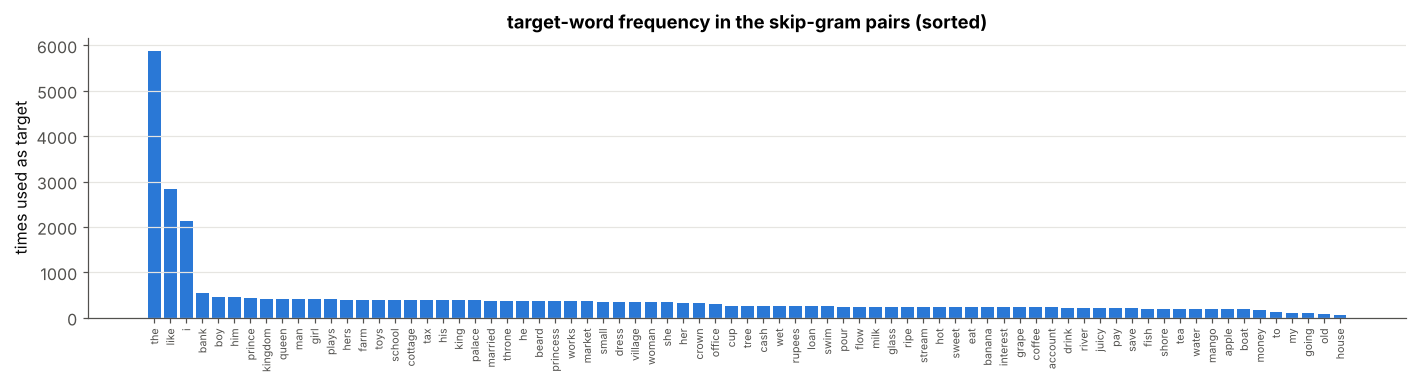

In [8]:
freq = np.bincount(pairs[:, 1], minlength=n)
order = np.argsort(-freq)
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(range(n), freq[order], color=C["blue"], width=0.8)
ax.set_xticks(range(n), [vocab[k] for k in order], rotation=90, fontsize=7)
ax.set_ylabel("times used as target"); ax.grid(axis="x", visible=False)
ax.set_title("target-word frequency in the skip-gram pairs (sorted)")
plt.tight_layout(); plt.show()

---
## 3 · The architecture 🏗️

From the notes (pages 10–11):

$$x\ (n\times1)\ \xrightarrow{\ V\ (d\times n)\ }\ h=Vx\ (d\times1)\ \xrightarrow{\ U\ (n\times d)\ }\ z=Uh\ (n\times1)\ \xrightarrow{\ \text{softmax}\ }\ y\ (n\times1)$$

* **No bias, no activation function** except the final softmax – the simplest network that can do the job.
* The hidden layer is small ($d\ll n$): every word must be squeezed through $d$ numbers – this **bottleneck** forces similar words to get similar codes.
* We want to read $z$ as a probability distribution over the $n$ words, hence softmax: $y_k=\dfrac{e^{z_k}}{\sum_{m=1}^n e^{z_m}}$.

📊 **Diagram** of the "bow-tie" (drawing code only):

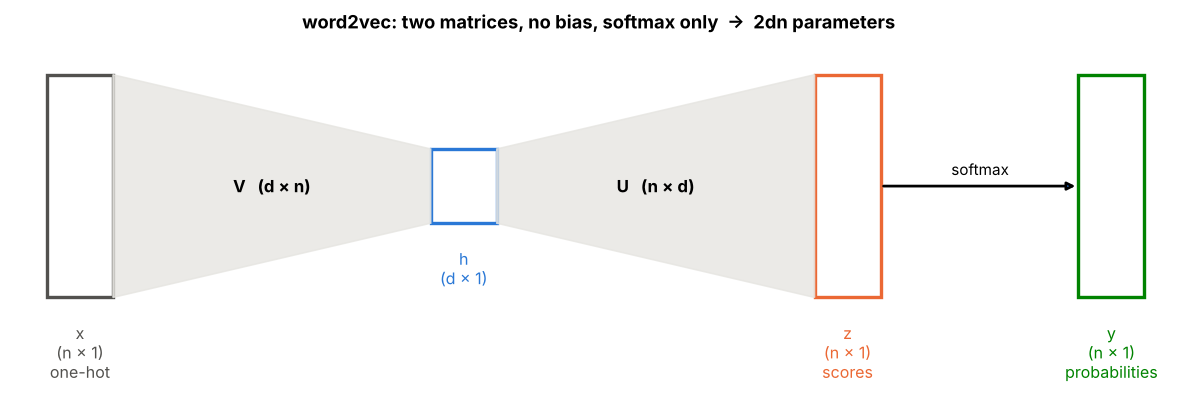

In [9]:
# ---------- plotting helper (visualisation only) ----------
fig, ax = plt.subplots(figsize=(11, 3.8))
def box(x0, h, label, col, w=0.55):
    ax.add_patch(plt.Rectangle((x0, -h / 2), w, h, fc="white", ec=col, lw=2.2))
    ax.text(x0 + w / 2, -h / 2 - 0.35, label, ha="center", va="top", fontsize=10.5, color=col)
box(0, 3.0, "x\n(n × 1)\none-hot", C["muted"])
box(3.2, 1.0, "h\n(d × 1)", C["blue"])
box(6.4, 3.0, "z\n(n × 1)\nscores", C["orange"])
box(8.6, 3.0, "y\n(n × 1)\nprobabilities", C["green"])
for (x0, x1, h0, h1, lab) in [(0.55, 3.2, 1.5, 0.5, "V   (d × n)"), (3.75, 6.4, 0.5, 1.5, "U   (n × d)")]:
    ax.fill([x0, x1, x1, x0], [h0, h1, -h1, -h0], color=C["grid"], alpha=0.8)
    ax.text((x0 + x1) / 2, 0, lab, ha="center", va="center", fontsize=11, fontweight="bold")
ax.annotate("", xy=(8.6, 0), xytext=(6.95, 0), arrowprops=dict(arrowstyle="-|>", lw=1.8))
ax.text(7.78, 0.15, "softmax", ha="center", fontsize=10)
ax.set_xlim(-0.3, 9.5); ax.set_ylim(-2.8, 2); ax.axis("off")
ax.set_title("word2vec: two matrices, no bias, softmax only  →  2dn parameters")
plt.tight_layout(); plt.show()

---
## 4 · Building the model, piece by piece 💻

As in module 02, the class is built one method per cell (methods attached with `Word2Vec.name = function`).

### 4.1 · Skeleton: the two matrices
`V` is $d\times n$ and `U` is $n\times d$, both filled with small random numbers (scale 0.1). Small, because large scores $z$ would make the softmax extremely confident before the model has learned anything; random (not zero), because if every word started with the same vector they would all receive the same updates and stay identical.

In [10]:
class Word2Vec:
    """x (one-hot, n) --V (d×n)--> h (d) --U (n×d)--> z (n) --softmax--> y (n). No biases."""

    def __init__(self, n, d, seed=0):
        rng = np.random.default_rng(seed)
        self.n, self.d = n, d
        self.V = rng.normal(0, 0.1, (d, n))      # input matrix: column k = word vector v_k
        self.U = rng.normal(0, 0.1, (n, d))      # output matrix: row k = output vector u_k

    def n_params(self):
        return self.V.size + self.U.size        # should be 2·d·n

### 4.2 · The hidden vector $h=Vx$ is a column lookup
With a one-hot $x$ (a 1 at position $c$), the matrix product picks out **column $c$** of $V$:

$$h=Vx=\sum_{k=1}^{n}x_k\ v_k=v_c\qquad\text{(notes, page 11: } h=\textstyle\sum_i x_iV_i\text{)}$$

So in code we never build $x$ or multiply by it – we just read `V[:, c]`. That saves $d\times n$ multiplications per example. For CBOW the hidden vector is the **average** of the context words' columns.

In [11]:
def hidden(self, c):
    """Skip-gram: h = V x = column c of V."""
    return self.V[:, c]


def hidden_cbow(self, context):
    """CBOW: h = average of the context words' columns."""
    return self.V[:, context].mean(axis=1)

Word2Vec.hidden, Word2Vec.hidden_cbow = hidden, hidden_cbow

**Check the lookup** against the full matrix-vector product with a real one-hot vector:

In [12]:
d = 10
model = Word2Vec(n, d)
c = index["king"]
x = np.zeros(n); x[c] = 1.0                       # one-hot vector of "king"
print("V @ x equals column c of V:", np.allclose(model.V @ x, model.hidden(c)))
print("multiplications: V @ x =", d * n, "  lookup = 0")

V @ x equals column c of V: True
multiplications: V @ x = 750   lookup = 0


### 4.3 · Scores and probabilities
$z=Uh$ gives one score per word, $z_k=u_k\cdot h$ – the dot product between word $k$'s **output vector** and the hidden vector. Softmax turns scores into probabilities (subtracting the maximum first for numerical safety, as in module 02).

In [13]:
def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()


def forward(self, c):
    """Skip-gram forward pass for input word c. Returns h, z, y."""
    h = self.hidden(c)                 # (d,)
    z = self.U @ h                     # (n,)  z_k = u_k · h
    y = softmax(z)                     # (n,)  probabilities
    return h, z, y

Word2Vec.forward = forward

### 4.4 · Prediction and the error
`predict` lists the most probable neighbours. `error` is the notes' $E=-\log y_o$ (page 11): minus the log of the probability the model gave to the **true** neighbour $o$. A perfect model ($y_o=1$) has $E=0$.

In [14]:
def predict(self, word, k=5):
    _, _, y = self.forward(index[word])
    top = np.argsort(-y)[:k]
    return [(vocab[j], round(float(y[j]), 3)) for j in top]


def error(self, c, o):
    _, _, y = self.forward(c)
    return -np.log(y[o])

Word2Vec.predict, Word2Vec.error = predict, error

---
## 5 · Counting parameters 🧮

Both matrices have $d\times n$ entries and there are no biases, so

$$\text{params}=\underbrace{d\ n}_{V}+\underbrace{n\ d}_{U}=2\ d\ n$$

In [15]:
print(f"toy model: d = {d}, n = {n}  →  2dn = {2 * d * n:,}   counted: {model.n_params():,}")
for d_, n_ in [(100, 10_000), (300, 100_000), (300, 3_000_000)]:
    p = 2 * d_ * n_
    print(f"d = {d_:>3}, n = {n_:>9,}  →  {p:>13,} parameters  ({4 * p / 1e9:5.2f} GB in float32)")

toy model: d = 10, n = 75  →  2dn = 1,500   counted: 1,500
d = 100, n =    10,000  →      2,000,000 parameters  ( 0.01 GB in float32)
d = 300, n =   100,000  →     60,000,000 parameters  ( 0.24 GB in float32)
d = 300, n = 3,000,000  →  1,800,000,000 parameters  ( 7.20 GB in float32)


The notes' typical setting ($d=300$, $n=10^5$) already has 60 million parameters – as many as a large image network, all for a model with a single hidden layer.

---
## 6 · What does an *untrained* model predict? 🎲

Random weights give scores close to 0, so the softmax spreads probability almost evenly: $y_k\approx1/n$. The expected error is then

$$E=-\log y_o\approx-\log\frac1n=\log n$$

In [16]:
print("untrained predictions for 'king':", model.predict("king"))
E_start = np.array([model.error(c_, o_) for c_, o_ in pairs[:2000]])
print(f"mean error on 2000 pairs = {E_start.mean():.3f}    log n = {np.log(n):.3f}")
_, _, y_king = model.forward(index["king"])          # kept for the plot below

untrained predictions for 'king': [('interest', 0.014), ('king', 0.014), ('milk', 0.014), ('tea', 0.014), ('shore', 0.014)]
mean error on 2000 pairs = 4.321    log n = 4.317


📊 **Plot:** the untrained model's probabilities for the input *king* (left) are almost flat at $1/n$; the errors of 2000 training pairs (right) cluster tightly around $\log n$.

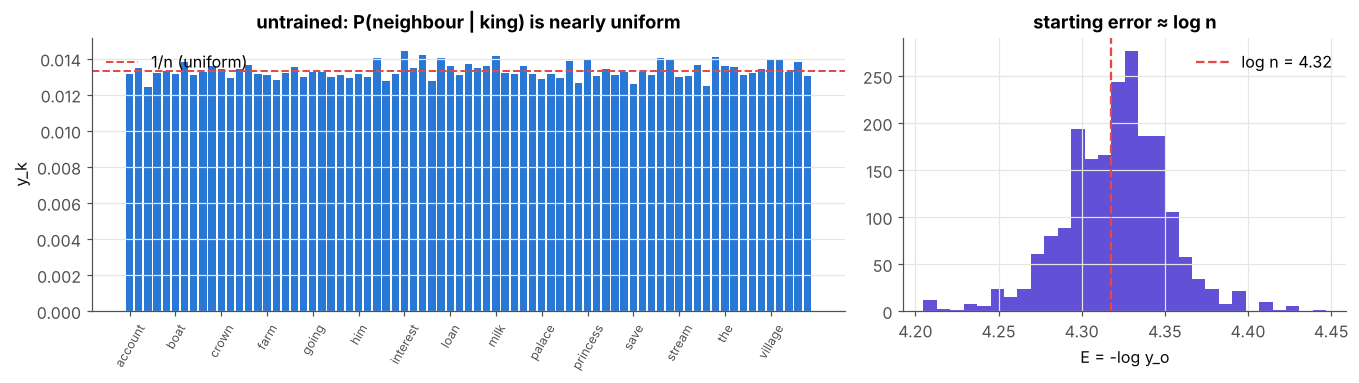

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.6), gridspec_kw=dict(width_ratios=[1.7, 1]))
axs[0].bar(range(n), y_king, color=C["blue"], width=0.8)
axs[0].axhline(1 / n, color=C["red"], ls="--", lw=1.3, label="1/n (uniform)")
axs[0].set_xticks(range(0, n, 5), [vocab[k] for k in range(0, n, 5)], rotation=60, fontsize=8)
axs[0].set_ylabel("y_k"); axs[0].set_title("untrained: P(neighbour | king) is nearly uniform"); axs[0].legend()
axs[0].grid(axis="x", visible=False)
axs[1].hist(E_start, bins=30, color=C["violet"])
axs[1].axvline(np.log(n), color=C["red"], ls="--", lw=1.5, label=f"log n = {np.log(n):.2f}")
axs[1].set_xlabel("E = -log y_o"); axs[1].set_title("starting error ≈ log n"); axs[1].legend()
plt.tight_layout(); plt.show()

---
## 7 · *"Where are my vectors?"* 🔍

The notes ask this on page 11 and answer: **each column of $V$.** Column $k$ of $V$ is what the network uses to represent word $w_k$ whenever it is the *input*, so after training it must contain everything needed to predict that word's neighbours – which is exactly its distributional meaning.

$U$ also contains one vector per word (its rows), used when the word is the *output*. Both are trained; by convention the columns of $V$ are reported as "the word embeddings" (some implementations average $V^\top$ and $U$).

In [18]:
show = ["king", "queen", "man", "woman", "mango", "apple"]
emb = model.V[:, [index[w] for w in show]]          # d × 6: the word vectors of these words
print("word vectors are the columns of V:", emb.shape)
cos = (emb / np.linalg.norm(emb, axis=0)).T @ (emb / np.linalg.norm(emb, axis=0))
print("cosine(king, queen) before training =", cos[0, 1].round(3), "  cosine(king, mango) =", cos[0, 4].round(3))

word vectors are the columns of V: (10, 6)
cosine(king, queen) before training = -0.066   cosine(king, mango) = -0.156


📊 **Plot:** the six word vectors as columns of numbers. Right now they are random noise – after training (notebook 06) *king* and *queen* will look alike and *mango* and *apple* will look alike.

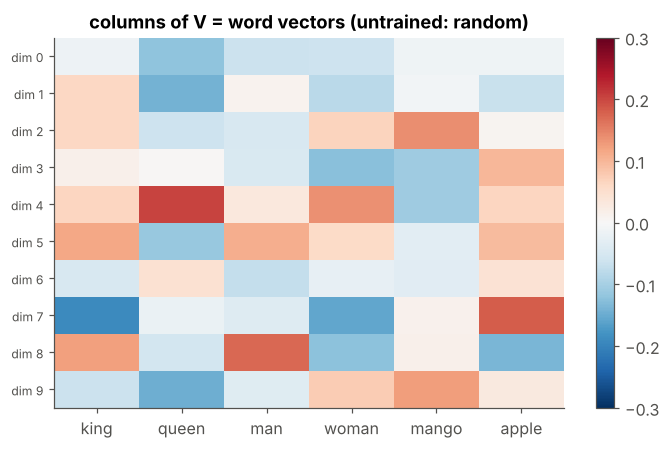

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
im = ax.imshow(emb, cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
ax.set_xticks(range(len(show)), show); ax.set_yticks(range(d), [f"dim {k}" for k in range(d)], fontsize=8)
plt.colorbar(im, ax=ax); ax.grid(False)
ax.set_title("columns of V = word vectors (untrained: random)")
plt.tight_layout(); plt.show()

---
## 8 · Summary 📌

| Item | Value |
|---|---|
| task | skip-gram: word → each neighbour; CBOW: neighbours → word |
| forward pass | $h=Vx=v_c$, $\ z=Uh$, $\ y=\text{softmax}(z)$ |
| error | $E=-\log y_o$ ($\approx\log n$ before training) |
| parameters | $2dn$ (no biases) |
| word vectors | columns of $V$ |

**Still missing:** how to change $V$ and $U$ to lower $E$. Notebook 05 derives the gradients of the softmax + $-\log$ error, step by step, exactly as in the notes (pages 12–14).

### ✍️ Try it yourself
1. How many skip-gram pairs does a sentence of length $L$ produce with window $m$ (ignore the sentence edges)? Check with `skipgram_pairs`.
2. Implement `forward_cbow(context)` using `hidden_cbow` and check that the output still sums to 1.
3. Initialise with scale 3 instead of 0.1. What happens to the untrained predictions and the starting error?
4. For $d=300$, how large must $n$ be before the model exceeds 1 GB in float32?

**Next →** `05 - Softmax and Cross-Entropy Gradients`